# CDS 4003 - Report: Model Building & Validation (CLO3)
**Project:** Predicting Road Accident Duration and Severity for Logistics Route Planning
**Data:** US Accidents (2016-2023), 500,000-row sample, prepared in the CLO2 report (497,097 rows)
**Targets:** `Severity` (classification, 4 classes) and `Duration_Minutes` (regression)

The notebook follows the four parts of the CLO3 rubric:
1. Model selection and justification
2. Model configuration and performance evaluation
3. Cross-validation and reliability analysis
4. Business alignment and deployment decision

In [1]:
import sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold,
                                     RandomizedSearchCV, cross_validate, cross_val_predict)
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (f1_score, accuracy_score, recall_score, precision_score,
                             classification_report, confusion_matrix,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.inspection import permutation_importance
from scipy.stats import randint, loguniform

sys.path.insert(0, '..')
from src.prep import prepare

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', None)
SEED = 42
BLUE, GREY, RED, ORANGE = '#2f6db5', '#9aa5b1', '#c0392b', '#e08e2b'


def save(name):
    plt.tight_layout()
    plt.savefig(f'figs/{name}.png', dpi=160)
    plt.show()

# 0. Data, split and success criteria
## 0.1 Load the prepared data
`prepare()` runs the same steps as the CLO2 notebook (same 497,097 rows and 36 columns). The only difference: it gives back the table **before** the missing values were filled. In CLO2 the mean and mode were taken from the whole file. Here we fill them inside the model pipeline, using the training data only, so the test data stays unseen (no data leakage).

In [2]:
clean, df = prepare('../data/US_Accidents_March23_sampled_500k.csv')
print('rows, columns:', df.shape)
print('missing cells (filled later, inside the pipeline):', int(df.isna().sum().sum()))

rows, columns: (497097, 36)
missing cells (filled later, inside the pipeline): 245101


## 0.2 Features
We use the same features for both targets. `Severity` is not used to predict `Duration_Minutes` and the duration is not used to predict `Severity`, because neither is known when the accident is first reported.
`City` and `County` are left out (9,466 and 1,602 values). `State`, latitude and longitude already give the location.

In [3]:
NUM = ['Start_Lat', 'Start_Lng', 'Temperature(F)', 'Humidity(%)', 'Pressure(in)',
       'Visibility(mi)', 'Wind_Speed(mph)', 'POI_Count', 'Hour', 'Month', 'Year']
PRECIP = ['Precipitation(in)']
FLAGS = ['Amenity', 'Bump', 'Crossing', 'Give_Way', 'Junction', 'No_Exit', 'Railway', 'Station',
         'Stop', 'Traffic_Calming', 'Traffic_Signal', 'Is_Weekend', 'Is_RushHour']
CAT = ['State', 'Timezone', 'Wind_Direction', 'Sunrise_Sunset', 'Weather_Group', 'Season',
       'DayOfWeek']
FEATURES = NUM + PRECIP + FLAGS + CAT

X = df[FEATURES].copy()
X[FLAGS] = X[FLAGS].astype(int)
y_sev = df['Severity']
y_dur = df['Duration_Minutes']
print('features:', len(FEATURES), '| numeric:', len(NUM) + 1, '| 0/1 flags:', len(FLAGS),
      '| text:', len(CAT))

features: 32 | numeric: 12 | 0/1 flags: 13 | text: 7


## 0.3 Train/test split
80% for training and 20% for testing. The split is stratified on `Severity`, so every class has the same share in both parts. The test set is used only once, at the end.

In [4]:
X_train, X_test, ys_train, ys_test, yd_train, yd_test = train_test_split(
    X, y_sev, y_dur, test_size=0.2, stratify=y_sev, random_state=SEED)
print('train:', X_train.shape, '| test:', X_test.shape)
print('Severity share in train (%):',
      (ys_train.value_counts(normalize=True).sort_index() * 100).round(2).to_dict())
print('Severity share in test  (%):',
      (ys_test.value_counts(normalize=True).sort_index() * 100).round(2).to_dict())

train: (397677, 32) | test: (99420, 32)
Severity share in train (%): {1: 0.86, 2: 79.59, 3: 16.99, 4: 2.57}
Severity share in test  (%): {1: 0.86, 2: 79.58, 3: 16.99, 4: 2.57}


## 0.4 Business success criteria (set before training)
A logistics dispatcher uses the predictions to decide whether to reroute a truck. We set the targets **before** looking at any results:
- **Severity:** the model must catch at least **50% of Severity 4 accidents** (the ones that block traffic the most), and its macro F1 must be **higher than the baseline**.
- **Duration:** the average error (MAE) must be **at least 10% lower than the baseline**, which guesses the same typical duration for every accident.

In [5]:
TARGET_RECALL_SEV4 = 0.50
TARGET_MAE_GAIN = 0.10

## 0.5 Preprocessing pipeline
Every model gets the same steps, and they are learned from the training rows only:
- numbers: fill gaps with the mean, then z-score scaling
- precipitation: fill gaps with 0 (no rain reported), then scaling
- 0/1 flags: used as they are
- text columns: fill gaps with the most frequent value, then one-hot (dummy) coding

In [6]:
preprocess = ColumnTransformer([
    ('num', Pipeline([('fill', SimpleImputer(strategy='mean')),
                      ('scale', StandardScaler())]), NUM),
    ('precip', Pipeline([('fill', SimpleImputer(strategy='constant', fill_value=0)),
                         ('scale', StandardScaler())]), PRECIP),
    ('flags', 'passthrough', FLAGS),
    ('cat', Pipeline([('fill', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]),
     CAT)])
n_cols = preprocess.fit(X_train.head(50000)).transform(X_train.head(5)).shape[1]
print('columns after preprocessing:', n_cols)

columns after preprocessing: 116


# 1. Model selection and justification
We compare a baseline with four models from the course (Chapter 5) for each target.

| Model | Severity (classification) | Duration (regression) | Why we use it |
|---|---|---|---|
| Baseline | most frequent class | median duration | the score to beat |
| Linear model | Logistic Regression | Linear Regression | simple, fast, easy to explain |
| Decision Tree | yes | yes | handles mixed data and non-linear rules, easy to explain |
| k-NN | yes | yes | uses similar past accidents (location, time, weather) |
| Random Forest | yes | yes | many trees together, usually more accurate than one tree |

Two settings come from the data:
- **Severity is imbalanced** (class 2 is 79.6%), so we use `class_weight='balanced'` where the model supports it, and we rank models by **macro F1**, not accuracy.
- **Duration is skewed to the right**, so the regression models learn `log(1 + minutes)` and we turn the prediction back into minutes. We rank them by **MAE in minutes**.

In [7]:
print('Severity counts in train:', ys_train.value_counts().sort_index().to_dict())
print('Duration in train: mean', round(yd_train.mean(), 1),
      '| median', round(yd_train.median(), 1), '| skewness', round(yd_train.skew(), 2))

Severity counts in train: {1: 3406, 2: 316492, 3: 67561, 4: 10218}
Duration in train: mean 108.3 | median 74.8 | skewness 3.51


In [8]:
def log_target(model):
    return TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1)

clf_models = {
    'Baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=SEED),
    'k-NN': KNeighborsClassifier(),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced',
                                            n_jobs=-1, random_state=SEED),
}
reg_models = {
    'Baseline': DummyRegressor(strategy='median'),
    'Linear Regression': log_target(LinearRegression()),
    'Decision Tree': log_target(DecisionTreeRegressor(random_state=SEED)),
    'k-NN': log_target(KNeighborsRegressor()),
    'Random Forest': log_target(RandomForestRegressor(n_estimators=100, n_jobs=-1,
                                                      random_state=SEED)),
}

# 2. Model configuration and hyperparameter tuning
## 2.1 Tuning sample
Tuning on all 397,677 training rows would take many hours on our laptop. So we tune and cross-validate on a **stratified sample of 60,000 training rows**. The final models are then trained on the full training set (k-NN on 100,000 rows, see Section 2.4).

In [9]:
X_tune, _, ys_tune, _, yd_tune, _ = train_test_split(
    X_train, ys_train, yd_train, train_size=60000, stratify=ys_train, random_state=SEED)
print('tuning sample:', X_tune.shape)
print('Severity counts in the sample:', ys_tune.value_counts().sort_index().to_dict())
cv3_c = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
cv3_r = KFold(n_splits=3, shuffle=True, random_state=SEED)

tuning sample: (60000, 32)
Severity counts in the sample: {1: 514, 2: 47751, 3: 10193, 4: 1542}


## 2.2 Search spaces
We use `RandomizedSearchCV` (Chapter 5: try alternative settings and keep the best). It tries random combinations from each range and scores them with 3-fold cross-validation.

In [10]:
clf_space = {
    'Logistic Regression': {'model__C': loguniform(0.01, 10)},
    'Decision Tree': {'model__max_depth': randint(4, 31),
                      'model__min_samples_leaf': randint(1, 201),
                      'model__criterion': ['gini', 'entropy']},
    'k-NN': {'model__n_neighbors': randint(3, 52), 'model__weights': ['uniform', 'distance']},
    'Random Forest': {'model__max_depth': [10, 15, 20, 25, None],
                      'model__min_samples_leaf': [1, 2, 5, 10, 20],
                      'model__max_features': ['sqrt', 0.3, 0.5]},
}
reg_space = {
    'Decision Tree': {'model__regressor__max_depth': randint(4, 31),
                      'model__regressor__min_samples_leaf': randint(1, 201)},
    'k-NN': {'model__regressor__n_neighbors': randint(3, 52),
             'model__regressor__weights': ['uniform', 'distance']},
    'Random Forest': {'model__regressor__max_depth': [10, 15, 20, 25, None],
                      'model__regressor__min_samples_leaf': [1, 2, 5, 10, 20],
                      'model__regressor__max_features': ['sqrt', 0.3, 0.5]},
}
N_ITER = {'Logistic Regression': 6, 'Decision Tree': 15, 'k-NN': 8, 'Random Forest': 10}

## 2.3 Default settings versus tuned settings
For each model we first score the default settings, then run the search. Both use the same 3 folds, so the scores can be compared directly. If the search does not beat the default settings, we keep the default settings.

In [11]:
def pipe(model):
    return Pipeline([('prep', preprocess), ('model', model)])

def tune(models, space, X_s, y_s, cv, scoring):
    rows, best = [], {}
    for name, model in models.items():
        t = time.time()
        default = cross_validate(pipe(model), X_s, y_s, cv=cv,
                                 scoring=scoring)['test_score'].mean()
        kept = 'default'
        tuned, params, best[name] = default, {}, pipe(model)
        if name in space:
            search = RandomizedSearchCV(pipe(model), space[name], n_iter=N_ITER.get(name, 10),
                                        cv=cv, scoring=scoring, random_state=SEED, n_jobs=1)
            search.fit(X_s, y_s)
            tuned = search.best_score_
            if tuned > default:   # keep the search result only if it is better
                params, best[name], kept = search.best_params_, search.best_estimator_, 'tuned'
        settings = {k.split('__')[-1]: (round(v, 3) if isinstance(v, float) else v)
                    for k, v in params.items()}
        rows.append([name, default, tuned, kept, settings, round(time.time() - t)])
    cols = ['model', 'default', 'best search', 'kept', 'settings used', 'seconds']
    return pd.DataFrame(rows, columns=cols), best

clf_tuning, clf_best = tune(clf_models, clf_space, X_tune, ys_tune, cv3_c, 'f1_macro')
clf_tuning[['default', 'best search']] = clf_tuning[['default', 'best search']].round(3)
print('Severity - macro F1 (3-fold CV on the tuning sample)')
print(clf_tuning.to_string(index=False))

Severity - macro F1 (3-fold CV on the tuning sample)
              model  default  best search    kept                                                 settings used  seconds
           Baseline    0.222        0.222 default                                                            {}        1
Logistic Regression    0.303        0.304   tuned                                                  {'C': 7.114}       89
      Decision Tree    0.379        0.337 default                                                            {}       35
               k-NN    0.315        0.273 default                                                            {}      103
      Random Forest    0.416        0.440   tuned {'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': 20}      129


In [12]:
reg_tuning, reg_best = tune(reg_models, reg_space, X_tune, yd_tune, cv3_r,
                            'neg_mean_absolute_error')
reg_tuning[['default', 'best search']] = (-reg_tuning[['default', 'best search']]).round(1)
print('Duration - MAE in minutes (3-fold CV on the tuning sample, lower is better)')
print(reg_tuning.to_string(index=False))

Duration - MAE in minutes (3-fold CV on the tuning sample, lower is better)
            model  default  best search    kept                              settings used  seconds
         Baseline     68.2         68.2 default                                         {}        1
Linear Regression     64.4         64.4 default                                         {}        2
    Decision Tree     81.3         61.0   tuned  {'max_depth': 15, 'min_samples_leaf': 58}       35
             k-NN     66.8         63.3   tuned {'n_neighbors': 38, 'weights': 'distance'}       96
    Random Forest     58.0         58.9 default                                         {}      275


# 3. Cross-validation and reliability
## 3.1 5-fold cross-validation of the tuned models
We run 5-fold cross-validation on the tuning sample with the tuned settings. The mean shows how good a model is, and the standard deviation shows how stable it is from fold to fold. We also keep the training score, to see if a model overfits (a big gap between training and validation).

This step comes before the test set, because we use the CV scores to choose the best model for each target. The test set is then only a final check (Sections 2.4 to 2.8 come after it).

In [13]:
cv5_c = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv5_r = KFold(n_splits=5, shuffle=True, random_state=SEED)

def cv5(best, X_s, y_s, cv, scoring, sign):
    rows, folds = [], {}
    for name, model in best.items():
        r = cross_validate(model, X_s, y_s, cv=cv, scoring=scoring, return_train_score=True)
        val, tr = sign * r['test_score'], sign * r['train_score']
        folds[name] = val
        rows.append([name, val.mean(), val.std(), val.min(), val.max(), tr.mean()])
    out = pd.DataFrame(rows, columns=['model', 'mean', 'std', 'min', 'max', 'train mean'])
    out['train - validation'] = out['train mean'] - out['mean']
    return out, folds

clf_cv, clf_folds = cv5(clf_best, X_tune, ys_tune, cv5_c, 'f1_macro', 1)
print('Severity - macro F1, 5-fold CV')
clf_cv.round(3)

Severity - macro F1, 5-fold CV


,model,mean,std,min,max,train mean,train - validation
0,Baseline,0.222,0.000,0.222,0.222,0.222,0.000
1,Logistic Regression,0.304,0.003,0.301,0.309,0.309,0.005
2,Decision Tree,0.387,0.017,0.370,0.409,0.999,0.612
3,k-NN,0.311,0.009,0.303,0.323,0.418,0.107
4,Random Forest,0.439,0.009,0.425,0.451,0.799,0.360


In [14]:
reg_cv, reg_folds = cv5(reg_best, X_tune, yd_tune, cv5_r, 'neg_mean_absolute_error', -1)
print('Duration - MAE in minutes, 5-fold CV')
reg_cv.round(1)

Duration - MAE in minutes, 5-fold CV


,model,mean,std,min,max,train mean,train - validation
0,Baseline,68.2,0.7,67.5,69.3,68.2,-0.0
1,Linear Regression,64.4,0.7,63.7,65.4,64.3,-0.1
2,Decision Tree,60.6,0.7,60.1,62.0,58.1,-2.5
3,k-NN,63.1,0.7,62.3,64.3,0.0,-63.1
4,Random Forest,57.8,0.6,57.2,58.9,26.0,-31.7


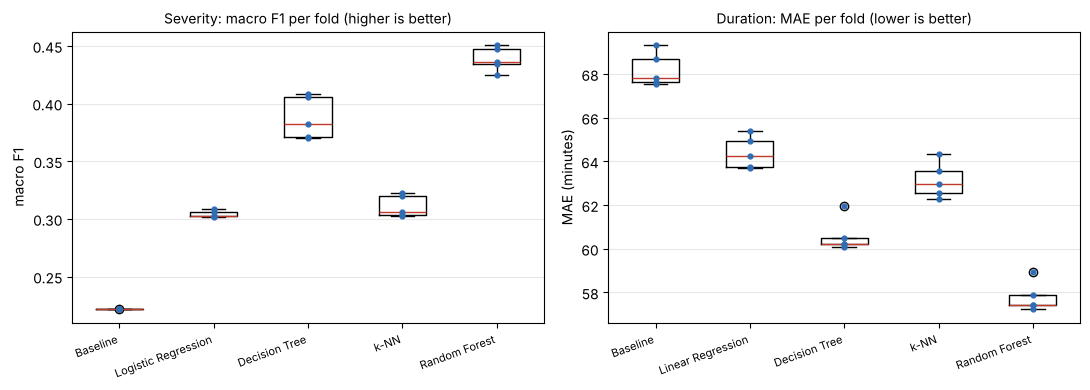

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, folds, title, ylab in [
        (axes[0], clf_folds, 'Severity: macro F1 per fold (higher is better)', 'macro F1'),
        (axes[1], reg_folds, 'Duration: MAE per fold (lower is better)', 'MAE (minutes)')]:
    names = list(folds)
    ax.boxplot([folds[n] for n in names], widths=0.5, medianprops={'color': RED})
    for i, n in enumerate(names, start=1):
        ax.scatter(np.full(5, i), folds[n], s=12, color=BLUE, zorder=3)
    ax.set_xticks(range(1, len(names) + 1))
    ax.set_xticklabels(names, rotation=20, ha='right', fontsize=8)
    ax.set_title(title, fontsize=10); ax.set_ylabel(ylab); ax.grid(axis='y', alpha=0.3)
save('01_cv_folds')

In [16]:
best_clf_name = clf_cv.loc[clf_cv['mean'].idxmax(), 'model']
best_reg_name = reg_cv.loc[reg_cv['mean'].idxmin(), 'model']
print('best Severity model (highest CV macro F1):', best_clf_name)
print('best Duration model (lowest CV MAE):', best_reg_name)

best Severity model (highest CV macro F1): Random Forest
best Duration model (lowest CV MAE): Random Forest


## 2.4 Final training and test results (back to Part 2)
Now every tuned model is trained on the full training set and scored once on the test set. k-NN keeps all training rows in memory and compares each new accident with all of them, so we train it on a 100,000-row sample to keep the prediction time reasonable.

In [17]:
X_knn, _, ys_knn, _, yd_knn, _ = train_test_split(
    X_train, ys_train, yd_train, train_size=100000, stratify=ys_train, random_state=SEED)

clf_final, clf_pred, clf_rows = {}, {}, []
for name, model in clf_best.items():
    Xf, yf = (X_knn, ys_knn) if name == 'k-NN' else (X_train, ys_train)
    t = time.time(); model.fit(Xf, yf); p = model.predict(X_test)
    clf_final[name], clf_pred[name] = model, p
    clf_rows.append([name, len(Xf), accuracy_score(ys_test, p),
                     f1_score(ys_test, p, average='macro'),
                     recall_score(ys_test, p, labels=[4], average='macro', zero_division=0),
                     precision_score(ys_test, p, labels=[4], average='macro', zero_division=0),
                     round(time.time() - t)])
clf_test = pd.DataFrame(clf_rows, columns=['model', 'train rows', 'accuracy', 'macro F1',
                                           'recall Sev 4', 'precision Sev 4', 'seconds'])
print('Severity - test set (99,420 accidents)')
clf_test.round(3)

Severity - test set (99,420 accidents)


,model,train rows,accuracy,macro F1,recall Sev 4,precision Sev 4,seconds
0,Baseline,397677,0.796,0.222,0.000,0.000,2
1,Logistic Regression,397677,0.446,0.302,0.512,0.062,50
2,Decision Tree,397677,0.771,0.441,0.137,0.123,13
3,k-NN,100000,0.787,0.331,0.005,0.182,38
4,Random Forest,397677,0.728,0.475,0.283,0.161,58


In [18]:
reg_final, reg_pred, reg_rows = {}, {}, []
for name, model in reg_best.items():
    Xf, yf = (X_knn, yd_knn) if name == 'k-NN' else (X_train, yd_train)
    t = time.time(); model.fit(Xf, yf); p = model.predict(X_test)
    reg_final[name], reg_pred[name] = model, p
    err = np.abs(yd_test - p)
    reg_rows.append([name, len(Xf), mean_absolute_error(yd_test, p),
                     np.sqrt(mean_squared_error(yd_test, p)), r2_score(yd_test, p),
                     np.median(err), (err <= 30).mean() * 100, round(time.time() - t)])
reg_test = pd.DataFrame(reg_rows, columns=['model', 'train rows', 'MAE', 'RMSE', 'R2',
                                           'median error', '% within 30 min', 'seconds'])
print('Duration - test set (99,420 accidents)')
reg_test.round(2)

Duration - test set (99,420 accidents)


,model,train rows,MAE,RMSE,R2,median error,% within 30 min,seconds
0,Baseline,397677,67.77,126.81,-0.07,44.93,34.94,2
1,Linear Regression,397677,63.91,124.91,-0.04,31.63,47.53,7
2,Decision Tree,397677,56.46,110.79,0.18,26.56,53.61,8
3,k-NN,100000,61.78,120.59,0.03,29.17,51.13,38
4,Random Forest,397677,53.45,104.34,0.27,24.73,56.12,381


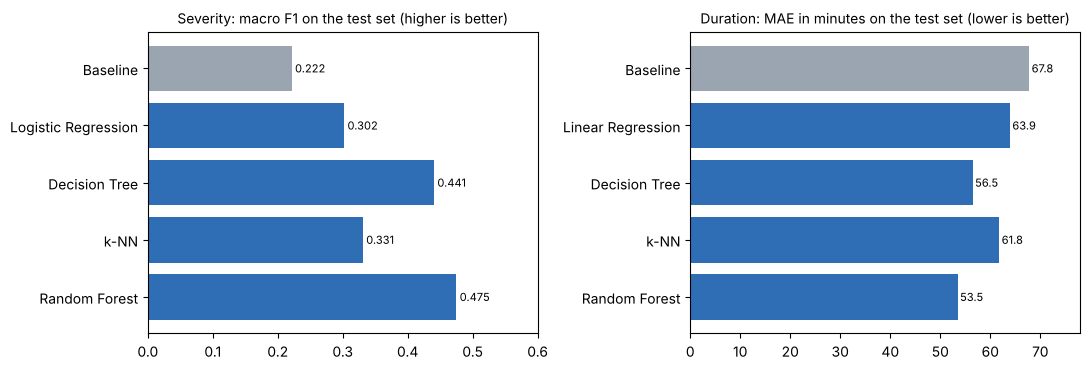

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
d = clf_test.set_index('model')
colors = [GREY if n == 'Baseline' else BLUE for n in d.index[::-1]]
axes[0].barh(d.index[::-1], d['macro F1'][::-1], color=colors)
for i, v in enumerate(d['macro F1'][::-1]):
    axes[0].text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=8)
axes[0].set_title('Severity: macro F1 on the test set (higher is better)', fontsize=10)
axes[0].set_xlim(0, 0.6)
d = reg_test.set_index('model')
colors = [GREY if n == 'Baseline' else BLUE for n in d.index[::-1]]
axes[1].barh(d.index[::-1], d['MAE'][::-1], color=colors)
for i, v in enumerate(d['MAE'][::-1]):
    axes[1].text(v + 0.5, i, f'{v:.1f}', va='center', fontsize=8)
axes[1].set_title('Duration: MAE in minutes on the test set (lower is better)', fontsize=10)
axes[1].set_xlim(0, d['MAE'].max() * 1.15)
save('02_test_comparison')

## 2.5 The best Severity model in detail
The classification report and the confusion matrix show the result for each class, not only the average.

In [20]:
p = clf_pred[best_clf_name]
print(best_clf_name)
print(classification_report(ys_test, p, digits=3))

Random Forest
              precision    recall  f1-score   support

           1      0.204     0.816     0.326       851
           2      0.926     0.741     0.823     79123
           3      0.437     0.730     0.546     16891
           4      0.161     0.283     0.205      2555

    accuracy                          0.728     99420
   macro avg      0.432     0.642     0.475     99420
weighted avg      0.817     0.728     0.756     99420



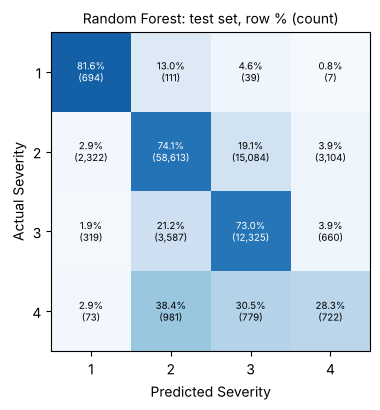

In [21]:
def plot_cm(y_true, y_pred, title, name):
    cm = confusion_matrix(y_true, y_pred, labels=[1, 2, 3, 4])
    share = cm / cm.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(5, 4.2))
    ax.imshow(share, cmap='Blues', vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f'{share[i, j]*100:.1f}%\n({cm[i, j]:,})', ha='center', va='center',
                    fontsize=7, color='white' if share[i, j] > 0.5 else 'black')
    ax.set_xticks(range(4)); ax.set_xticklabels([1, 2, 3, 4])
    ax.set_yticks(range(4)); ax.set_yticklabels([1, 2, 3, 4])
    ax.set_xlabel('Predicted Severity'); ax.set_ylabel('Actual Severity')
    ax.set_title(title, fontsize=10)
    save(name)
    return cm

cm_default = plot_cm(ys_test, p, f'{best_clf_name}: test set, row % (count)',
                     '03_confusion_default')

## 2.6 Cost-sensitive decision rule for Severity 4
A missed Severity 4 accident costs the most, because the truck drives into a long blockage. In Chapter 5 we used MetaCost for this kind of problem. Here we do the same idea by changing the decision rule: the model says "Severity 4" when its probability for class 4 is above a threshold, even if another class has a higher probability.

We pick the threshold on the **training data** with 5-fold out-of-fold probabilities (each training row is scored by a model that did not see it), not on the test set. We choose the highest threshold that still catches at least 50% of Severity 4 accidents, because a higher threshold gives fewer false alarms.

In [22]:
model_c = clf_best[best_clf_name]
proba_oof = cross_val_predict(model_c, X_train, ys_train, cv=cv5_c, method='predict_proba')
classes = np.array([1, 2, 3, 4])

def apply_rule(proba, t):
    pred = classes[proba.argmax(axis=1)]
    pred[proba[:, 3] >= t] = 4
    return pred

rows = []
for t in np.round(np.arange(0.05, 0.96, 0.01), 2):
    pr = apply_rule(proba_oof, t)
    rows.append([t, recall_score(ys_train, pr, labels=[4], average='macro'),
                 precision_score(ys_train, pr, labels=[4], average='macro', zero_division=0),
                 f1_score(ys_train, pr, average='macro'), (pr == 4).mean() * 100])
curve = pd.DataFrame(rows, columns=['threshold', 'recall Sev 4', 'precision Sev 4', 'macro F1',
                                    '% flagged as Sev 4'])
ok = curve[curve['recall Sev 4'] >= TARGET_RECALL_SEV4]
THRESHOLD = ok['threshold'].max()
print('chosen threshold:', THRESHOLD)
show = curve[curve['threshold'].isin(sorted({0.1, 0.2, 0.3, THRESHOLD, 0.5}))]
print(show.round(3).to_string(index=False))

chosen threshold: 0.28
 threshold  recall Sev 4  precision Sev 4  macro F1  % flagged as Sev 4
      0.10         0.838            0.051     0.367              42.362
      0.20         0.673            0.073     0.422              23.754
      0.28         0.516            0.097     0.449              13.742
      0.30         0.477            0.104     0.455              11.774
      0.50         0.254            0.162     0.474               4.033


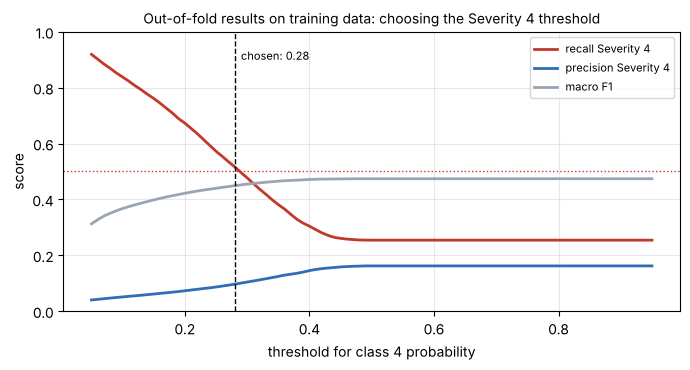

In [23]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(curve['threshold'], curve['recall Sev 4'], color=RED, lw=2, label='recall Severity 4')
ax.plot(curve['threshold'], curve['precision Sev 4'], color=BLUE, lw=2,
        label='precision Severity 4')
ax.plot(curve['threshold'], curve['macro F1'], color=GREY, lw=2, label='macro F1')
ax.axhline(TARGET_RECALL_SEV4, color=RED, ls=':', lw=1)
ax.axvline(THRESHOLD, color='black', ls='--', lw=1)
ax.text(THRESHOLD + 0.01, 0.9, f'chosen: {THRESHOLD}', fontsize=8)
ax.set_xlabel('threshold for class 4 probability'); ax.set_ylabel('score'); ax.set_ylim(0, 1)
ax.set_title('Out-of-fold results on training data: choosing the Severity 4 threshold',
             fontsize=10)
ax.legend(fontsize=8); ax.grid(alpha=0.3)
save('04_threshold')

Random Forest with threshold 0.28 for class 4 - test set
              precision    recall  f1-score   support

           1      0.204     0.812     0.326       851
           2      0.930     0.675     0.782     79123
           3      0.444     0.627     0.520     16891
           4      0.097     0.559     0.165      2555

    accuracy                          0.665     99420
   macro avg      0.419     0.668     0.448     99420
weighted avg      0.820     0.665     0.718     99420



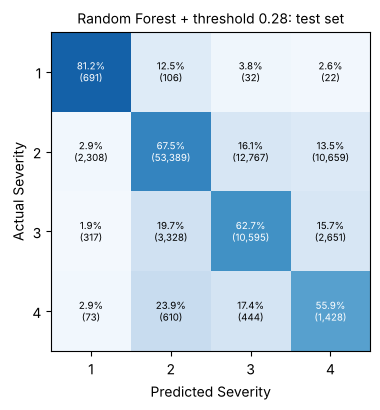

In [24]:
proba_test = clf_final[best_clf_name].predict_proba(X_test)
p_rule = apply_rule(proba_test, THRESHOLD)
print(f'{best_clf_name} with threshold {THRESHOLD} for class 4 - test set')
print(classification_report(ys_test, p_rule, digits=3))
cm_rule = plot_cm(ys_test, p_rule, f'{best_clf_name} + threshold {THRESHOLD}: test set',
                  '05_confusion_rule')

## 2.7 The best Duration model in detail

In [25]:
pd_best = reg_pred[best_reg_name]
bins = [5, 30, 60, 120, 240, 1440]
labels = ['5-30', '30-60', '60-120', '120-240', '240-1440']
grp = pd.cut(yd_test, bins=bins, labels=labels, include_lowest=True)
pred = pd.Series(pd_best, index=yd_test.index)
by_range = pd.DataFrame({'accidents': grp.value_counts().reindex(labels),
                         'actual median': yd_test.groupby(grp).median().reindex(labels),
                         'predicted median': pred.groupby(grp).median().reindex(labels),
                         'MAE': (yd_test - pd_best).abs().groupby(grp).mean().reindex(labels)})
print(best_reg_name, '- error by actual duration range (minutes)')
by_range.round(1)

Random Forest - error by actual duration range (minutes)


,accidents,actual median,predicted median,MAE
Duration_Minutes,,,,
5-30,24528,29.6,49.2,28.8
30-60,20870,45.0,61.7,24.5
60-120,26641,79.4,78.3,22.5
120-240,17705,140.8,95.8,56.2
240-1440,9676,360.0,112.4,258.5


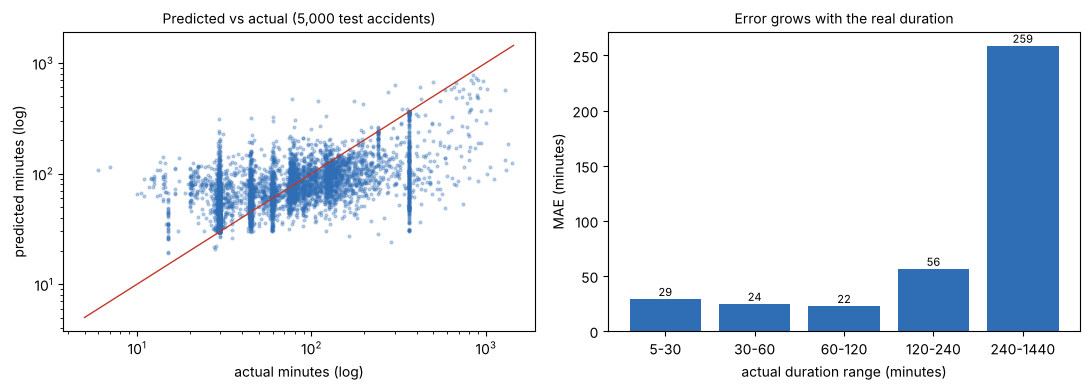

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
s = np.random.RandomState(SEED).choice(len(yd_test), 5000, replace=False)
axes[0].scatter(yd_test.values[s], pd_best[s], s=4, alpha=0.3, color=BLUE)
axes[0].plot([5, 1440], [5, 1440], color=RED, lw=1)
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel('actual minutes (log)'); axes[0].set_ylabel('predicted minutes (log)')
axes[0].set_title('Predicted vs actual (5,000 test accidents)', fontsize=10)
axes[1].bar(labels, by_range['MAE'], color=BLUE)
for i, v in enumerate(by_range['MAE']):
    axes[1].text(i, v + 3, f'{v:.0f}', ha='center', fontsize=8)
axes[1].set_xlabel('actual duration range (minutes)'); axes[1].set_ylabel('MAE (minutes)')
axes[1].set_title('Error grows with the real duration', fontsize=10)
save('06_duration_errors')

## 2.8 Which features matter
We use permutation importance on 10,000 test accidents: shuffle one feature and see how much the score drops. A big drop means the model depends on that feature.

In [27]:
s = X_test.sample(10000, random_state=SEED).index
imp_c = permutation_importance(clf_final[best_clf_name], X_test.loc[s], ys_test.loc[s],
                               scoring='f1_macro', n_repeats=3, random_state=SEED, n_jobs=1)
imp_r = permutation_importance(reg_final[best_reg_name], X_test.loc[s], yd_test.loc[s],
                               scoring='neg_mean_absolute_error', n_repeats=3,
                               random_state=SEED, n_jobs=1)
imp = pd.DataFrame({'Severity (drop in macro F1)': imp_c.importances_mean,
                    'Duration (rise in MAE, minutes)': imp_r.importances_mean}, index=FEATURES)
imp.sort_values('Severity (drop in macro F1)', ascending=False).head(10).round(4)

,Severity (drop in macro F1),"Duration (rise in MAE, minutes)"
Year,0.1381,20.9377
Start_Lat,0.0316,5.0215
Start_Lng,0.0271,5.1239
Hour,0.0189,4.0141
State,0.0178,4.5272
Month,0.0158,7.5455
Traffic_Signal,0.0137,0.2433
Crossing,0.0039,0.0630
Stop,0.0033,0.0061
Is_RushHour,0.0029,1.6457


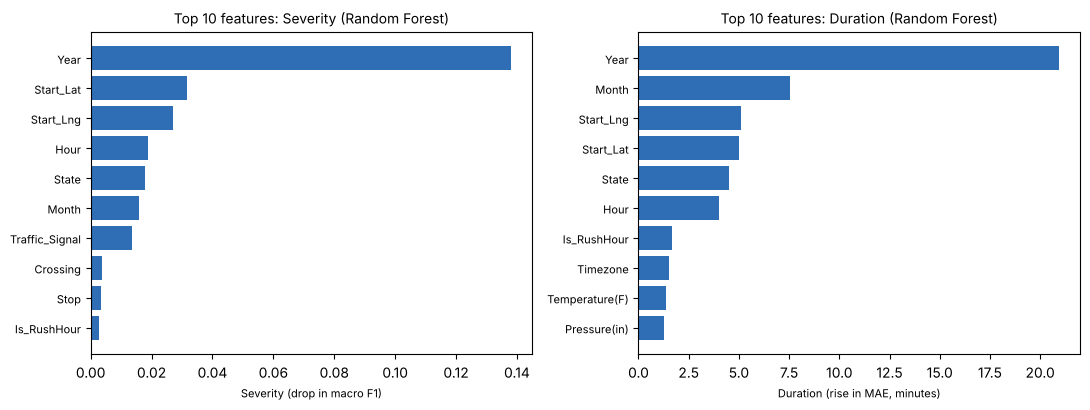

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, col, title in [
        (axes[0], 'Severity (drop in macro F1)', f'Severity ({best_clf_name})'),
        (axes[1], 'Duration (rise in MAE, minutes)', f'Duration ({best_reg_name})')]:
    top = imp[col].sort_values().tail(10)
    ax.barh(top.index, top.values, color=BLUE)
    ax.set_title(f'Top 10 features: {title}', fontsize=10); ax.set_xlabel(col, fontsize=8)
    ax.tick_params(axis='y', labelsize=8)
save('07_importance')

## 3.2 Stability over time
The data covers 2016 to 2023. If the model works well in some years and badly in others, it is not reliable. We score the final models on the test accidents of each year.

In [29]:
year = X_test['Year']
stab = pd.DataFrame({
    'test accidents': year.value_counts().sort_index(),
    'Severity 4 share %': (ys_test == 4).groupby(year).mean() * 100,
    'macro F1': pd.Series({y: f1_score(ys_test[year == y], p_rule[(year == y).values],
                                       average='macro')
                           for y in sorted(year.unique())}),
    'recall Sev 4': pd.Series({y: recall_score(ys_test[year == y], p_rule[(year == y).values],
                                               labels=[4], average='macro', zero_division=0)
                               for y in sorted(year.unique())}),
    'Duration MAE': (yd_test - pd_best).abs().groupby(year).mean(),
    'Baseline MAE': (yd_test - yd_train.median()).abs().groupby(year).mean(),
})
stab.round(3)

,test accidents,Severity 4 share %,macro F1,recall Sev 4,Duration MAE,Baseline MAE
2016,5335,3.261,0.337,0.661,79.142,111.975
2017,9231,3.402,0.346,0.608,72.959,97.115
2018,11516,2.840,0.347,0.517,39.368,64.076
2019,12514,2.933,0.347,0.534,28.570,40.016
2020,15049,2.492,0.453,0.469,54.797,71.547
2021,19985,1.831,0.341,0.505,65.716,76.968
2022,22604,2.389,0.357,0.602,49.411,53.262
2023,3186,2.888,0.514,0.772,47.926,58.477


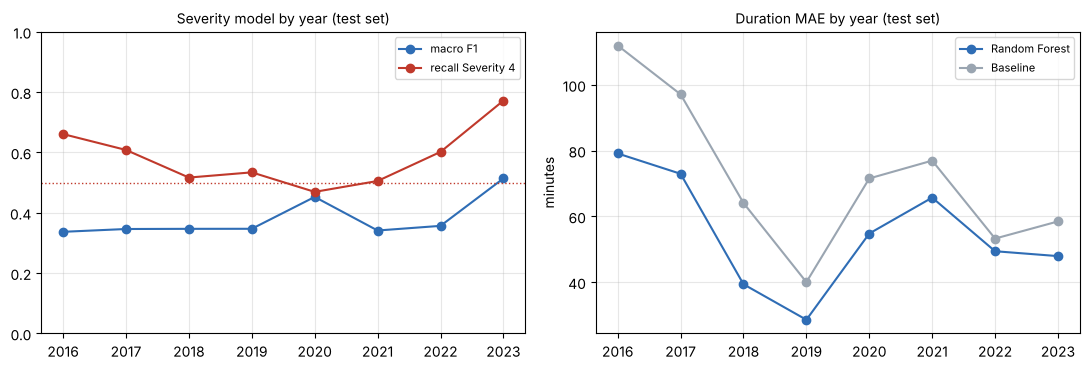

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(stab.index, stab['macro F1'], marker='o', color=BLUE, label='macro F1')
axes[0].plot(stab.index, stab['recall Sev 4'], marker='o', color=RED, label='recall Severity 4')
axes[0].axhline(TARGET_RECALL_SEV4, color=RED, ls=':', lw=1)
axes[0].set_ylim(0, 1); axes[0].legend(fontsize=8)
axes[0].set_title('Severity model by year (test set)', fontsize=10)
axes[1].plot(stab.index, stab['Duration MAE'], marker='o', color=BLUE, label=best_reg_name)
axes[1].plot(stab.index, stab['Baseline MAE'], marker='o', color=GREY, label='Baseline')
axes[1].set_title('Duration MAE by year (test set)', fontsize=10)
axes[1].set_ylabel('minutes'); axes[1].legend(fontsize=8)
for ax in axes: ax.grid(alpha=0.3); ax.set_xticks(stab.index)
save('08_by_year')

Year is the most important feature for both models (Section 2.8). This can be a risk: the model may learn how accidents were recorded in each year, not what happened on the road, and future years are not in the data. We check how much the models depend on it with 5-fold CV on the tuning sample, with and without `Year`.

In [31]:
no_year = [f for f in FEATURES if f != 'Year']
prep_no_year = ColumnTransformer([
    ('num', Pipeline([('fill', SimpleImputer(strategy='mean')),
                      ('scale', StandardScaler())]), [c for c in NUM if c != 'Year']),
    ('precip', Pipeline([('fill', SimpleImputer(strategy='constant', fill_value=0)),
                         ('scale', StandardScaler())]), PRECIP),
    ('flags', 'passthrough', FLAGS),
    ('cat', Pipeline([('fill', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]),
     CAT)])

rows = []
for target, best, y_s, cv, scoring, sign, name in [
        ('Severity macro F1', clf_best, ys_tune, cv5_c, 'f1_macro', 1, best_clf_name),
        ('Duration MAE', reg_best, yd_tune, cv5_r, 'neg_mean_absolute_error', -1,
         best_reg_name)]:
    r = cross_validate(best[name], X_tune, y_s, cv=cv, scoring=scoring)
    with_year = sign * r['test_score']
    m = Pipeline([('prep', prep_no_year), ('model', clone(best[name].named_steps['model']))])
    r = cross_validate(m, X_tune[no_year], y_s, cv=cv, scoring=scoring)
    without = sign * r['test_score']
    rows.append([target, with_year.mean(), without.mean()])
year_check = pd.DataFrame(rows, columns=['5-fold CV score', 'with Year', 'without Year'])
print(year_check.round(3).to_string(index=False))

  5-fold CV score  with Year  without Year
Severity macro F1      0.439         0.375
     Duration MAE     57.777        64.316


## 3.3 Cross-validation compared with the test set
If the 5-fold CV score and the test score are close, the CV result was a fair estimate and the model is not just lucky on one split.

In [32]:
cmp = pd.DataFrame({
    'Severity macro F1': [clf_cv.set_index('model').loc[best_clf_name, 'mean'],
                          clf_test.set_index('model').loc[best_clf_name, 'macro F1']],
    'Duration MAE': [reg_cv.set_index('model').loc[best_reg_name, 'mean'],
                     reg_test.set_index('model').loc[best_reg_name, 'MAE']],
}, index=['5-fold CV (60,000 rows)', 'test set (99,420 rows)'])
cmp.round(3)

,Severity macro F1,Duration MAE
"5-fold CV (60,000 rows)",0.439,57.777
"test set (99,420 rows)",0.475,53.451


# 4. Business alignment and go/no-go decision
We compare the final results with the criteria from Section 0.4.

In [33]:
base_f1 = clf_test.set_index('model').loc['Baseline', 'macro F1']
rule_f1 = f1_score(ys_test, p_rule, average='macro')
rule_rec4 = recall_score(ys_test, p_rule, labels=[4], average='macro')
rule_prec4 = precision_score(ys_test, p_rule, labels=[4], average='macro')
base_mae = reg_test.set_index('model').loc['Baseline', 'MAE']
best_mae = reg_test.set_index('model').loc[best_reg_name, 'MAE']
gain = (base_mae - best_mae) / base_mae

decision = pd.DataFrame([
    ['Severity', 'recall on Severity 4 >= 50%', f'{rule_rec4*100:.1f}%',
     'met' if rule_rec4 >= TARGET_RECALL_SEV4 else 'not met'],
    ['Severity', 'macro F1 higher than baseline', f'{rule_f1:.3f} vs {base_f1:.3f}',
     'met' if rule_f1 > base_f1 else 'not met'],
    ['Duration', 'MAE at least 10% lower than baseline',
     f'{best_mae:.1f} vs {base_mae:.1f} min ({gain*100:.1f}% lower)',
     'met' if gain >= TARGET_MAE_GAIN else 'not met'],
], columns=['target', 'criterion', 'result on test set', 'status'])
print('Severity 4 alerts: precision', round(rule_prec4, 3),
      '-> about', round(1 / rule_prec4, 1), 'alerts for each real Severity 4 accident')
decision

Severity 4 alerts: precision 0.097 -> about 10.3 alerts for each real Severity 4 accident


,target,criterion,result on test set,status
0,Severity,recall on Severity 4 >= 50%,55.9%,met
1,Severity,macro F1 higher than baseline,0.448 vs 0.222,met
2,Duration,MAE at least 10% lower than baseline,53.5 vs 67.8 min (21.1% lower),met


In [34]:
n4 = int((ys_test == 4).sum())
caught = int(((p_rule == 4) & (ys_test.values == 4)).sum())
alerts = int((p_rule == 4).sum())
caught_default = int(((clf_pred[best_clf_name] == 4) & (ys_test.values == 4)).sum())
print('Severity 4 accidents in the test set:', n4)
print('caught with the normal rule      :', caught_default)
print('caught with the threshold rule   :', caught)
print('Severity 4 alerts raised          :', alerts, '| false alarms:', alerts - caught)
share = alerts / len(ys_test) * 100
print('share of all test accidents flagged as Severity 4: %.1f%%' % share)

Severity 4 accidents in the test set: 2555
caught with the normal rule      : 722
caught with the threshold rule   : 1428
Severity 4 alerts raised          : 14760 | false alarms: 13332
share of all test accidents flagged as Severity 4: 14.8%
